In [17]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import pandas as pd

## Extracción de Datos

In [18]:
# Jupyter ejecuta el notebook desde su propia carpeta ("Calibraciones 12-11-2026"),
# así que las rutas relativas funcionan en cualquier clon del repositorio.
BASE = Path.cwd()

RUTA_REF = BASE / "17019_segundos_2026-11-13T08-39.dat"
# El experimento empezó el 12-11 y terminó el 13-11 (pasó la medianoche),
# así que cada domo tiene 2 archivos. Esta vez los 4 RTC tienen la hora correcta.
RUTAS_DOMOS = {
    "Domo 1": [BASE / "Domo_1" / "20261112.csv", BASE / "Domo_1" / "20261113.csv"],
    "Domo 2": [BASE / "Domo_2" / "20261112.csv", BASE / "Domo_2" / "20261113.csv"],
    "Domo 3": [BASE / "Domo_3" / "20261112.csv", BASE / "Domo_3" / "20261113.csv"],
    "Domo 4": [BASE / "Domo_4" / "20261112.csv", BASE / "Domo_4" / "20261113.csv"],
}

# Avisa con un mensaje claro si falta algún archivo, antes de intentar leer.
faltantes = [r for r in [RUTA_REF, *sum(RUTAS_DOMOS.values(), [])] if not r.exists()]
if faltantes:
    raise FileNotFoundError(
        "No se encontraron estos archivos:\n  "
        + "\n  ".join(str(r.relative_to(BASE)) for r in faltantes)
    )

def leer_referencia(ruta):
    """Archivo TOA5 del Campbell CR300.
    Encabezado: fila 0 = metadatos, 1 = nombres, 2 = unidades, 3 = tipo de dato."""
    return pd.read_csv(
        ruta,
        skiprows=[0, 2, 3],
        na_values=["NAN"],
        parse_dates=["TIMESTAMP"],
        index_col="TIMESTAMP",
    )

def leer_domo(rutas):
    """Lee uno o varios CSV de un mismo domo y los une en una sola serie de tiempo."""
    partes = []
    for ruta in rutas:
        df = pd.read_csv(ruta, parse_dates=["Timestamp"])
        df["archivo"] = ruta.name  # de qué archivo viene cada fila
        partes.append(df)
    df = pd.concat(partes, ignore_index=True)

    # Quita la fila que escribe el firmware al encender (todos los sensores en NaN).
    sensores = df.columns.difference(["Timestamp", "Timeon", "archivo"])
    df = df.dropna(subset=sensores, how="all")

    return df.set_index("Timestamp")

# Un DataFrame independiente por fuente, todos en un mismo diccionario.
datos = {"Referencia": leer_referencia(RUTA_REF)}
for nombre, rutas in RUTAS_DOMOS.items():
    datos[nombre] = leer_domo(rutas)

# Accesos directos (son los mismos objetos que hay en `datos`).
df_ref = datos["Referencia"]
df_d1 = datos["Domo 1"]
df_d2 = datos["Domo 2"]
df_d3 = datos["Domo 3"]
df_d4 = datos["Domo 4"]

# Resumen
for nombre, df in datos.items():
    print(f"{nombre:<10} {len(df):>6} filas  {df.index.min()} -> {df.index.max()}")


Referencia   8593 filas  2026-11-12 08:47:10 -> 2026-11-13 08:39:10
Domo 1      86336 filas  2026-11-12 08:44:42 -> 2026-11-13 08:44:30
Domo 2      86268 filas  2026-11-12 08:44:03 -> 2026-11-13 08:43:15
Domo 3      86239 filas  2026-11-12 08:43:13 -> 2026-11-13 08:41:57
Domo 4      86226 filas  2026-11-12 08:42:26 -> 2026-11-13 08:40:52


## Revisión de comportamiento de Datos

In [19]:
# ---------------------------------------------------------------------------
# Datos del experimento (sin sincronización: los 4 RTC tenían la hora correcta)
# ---------------------------------------------------------------------------
FECHA = "2026-11-12"      # día de inicio del experimento
FECHA_FIN = "2026-11-13"  # el experimento pasó la medianoche y terminó este día
ESTACIONES = ["Domo 1", "Domo 2", "Domo 3", "Domo 4"]

# Se toma directamente de `datos` todo el rango FECHA -> FECHA_FIN (ambos días completos).
exp = {nombre: df.loc[FECHA:FECHA_FIN].sort_index() for nombre, df in datos.items()}

# El SHT40 entrega valores en los extremos de su escala cuando falla la lectura
# (-45 / -37.7 / 130 °C, 0 / 100 %). Se marcan como NaN para no graficarlos.
for nombre in ESTACIONES:
    df = exp[nombre]
    invalido = ~(df["SHT_Temp"].between(-40, 125, inclusive="neither")
                 & df["SHT_Hum"].between(0, 100, inclusive="neither"))
    exp[nombre] = df.assign(
        SHT_Temp=df["SHT_Temp"].mask(invalido),
        SHT_Hum=df["SHT_Hum"].mask(invalido),
    )

COLORES = {"Domo 1": "#2a78d6", "Domo 2": "#eb6834", "Domo 3": "#1baf7a", "Domo 4": "#eda100"}
COLOR_REF = "#3d3d3a"
COLOR_GRILLA = "#e4e3df"


def graficar_vs_referencia(exp, col_domo, col_ref, etiqueta, titulo, margen, sensor="SHT40"):
    """Un panel por estación: SHT40 (color) vs. referencia (línea discontinua).

    La escala Y es la misma en todos los paneles y se ajusta al rango de la
    referencia ± `margen`; los puntos que quedan fuera se cuentan en el panel.
    """
    ref = exp["Referencia"][col_ref]
    y_min, y_max = ref.min() - margen, ref.max() + margen

    fig, ejes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True,
                             layout="constrained")
    for ax, nombre in zip(ejes.flat, ESTACIONES):
        serie = exp[nombre][col_domo]
        ax.plot(serie.index, serie, lw=1.2, color=COLORES[nombre], label=f"{nombre} ({sensor})")
        ax.plot(ref.index, ref, lw=1.5, ls="--", color=COLOR_REF, label="Referencia")

        fuera = int(((serie < y_min) | (serie > y_max)).sum())
        validos = int(serie.notna().sum())
        nota = f"{validos} lecturas válidas"
        if fuera:
            nota += f"\n{fuera} fuera de escala"
        ax.text(0.99, 0.03, nota, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=8, color="#5f5e5a")

        ax.set_title(nombre, loc="left", fontsize=11)
        ax.legend(loc="upper left", frameon=False, fontsize=8)
        ax.grid(True, color=COLOR_GRILLA, lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)

    ejes[0, 0].set_ylim(y_min, y_max)
    for ax in ejes[:, 0]:
        ax.set_ylabel(etiqueta)
    for ax in ejes[-1]:
        # Se muestra el día porque el experimento cruza la medianoche.
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m %H:%M"))
        ax.set_xlabel("Fecha y hora")
    fig.suptitle(titulo)
    return fig, ejes

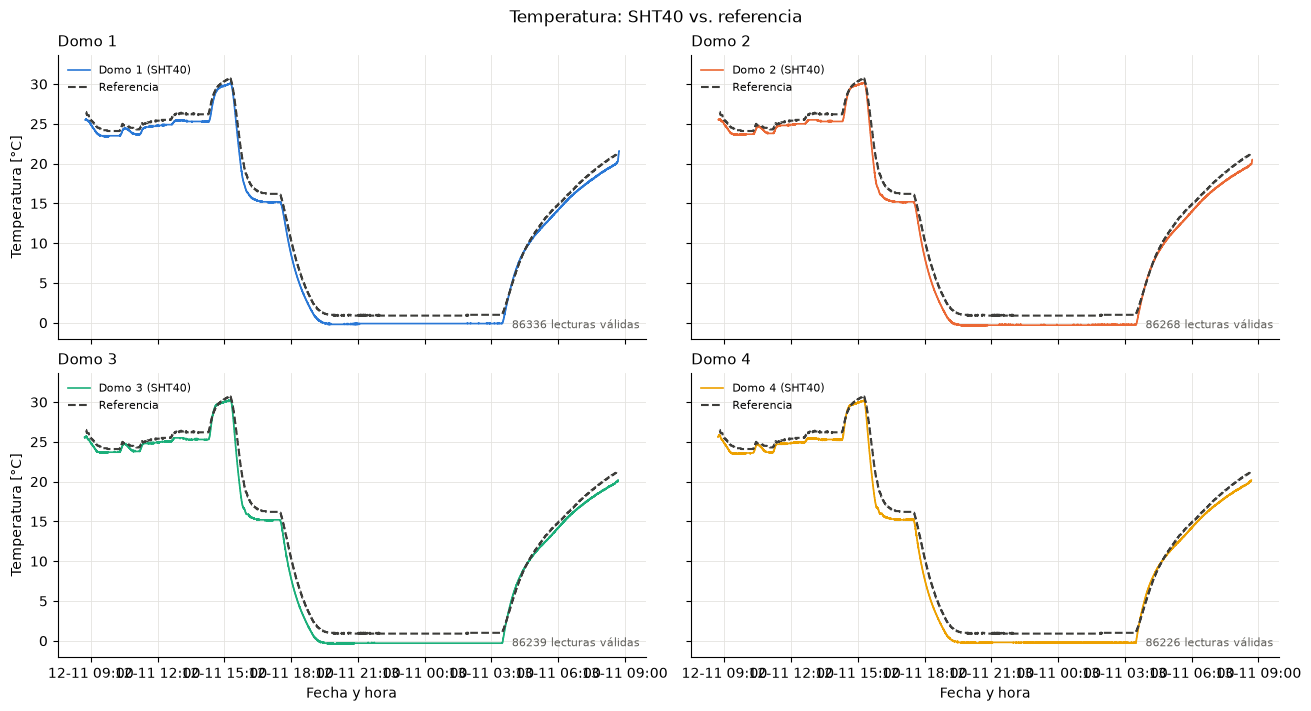

In [20]:
fig_t, _ = graficar_vs_referencia(exp, "SHT_Temp", "AirT_C", "Temperatura [°C]",
                                  "Temperatura: SHT40 vs. referencia", margen=3)
plt.show()

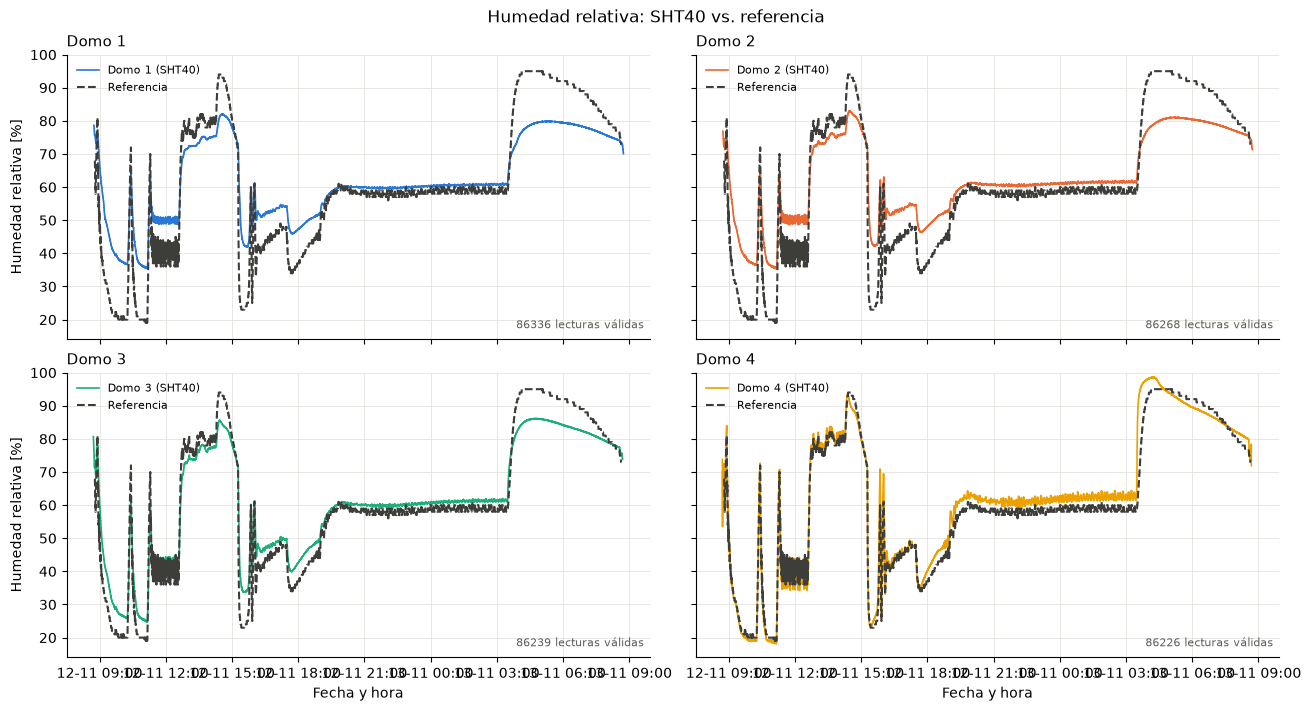

In [21]:
fig_h, _ = graficar_vs_referencia(exp, "SHT_Hum", "RH", "Humedad relativa [%]",
                                  "Humedad relativa: SHT40 vs. referencia", margen=5)
plt.show()

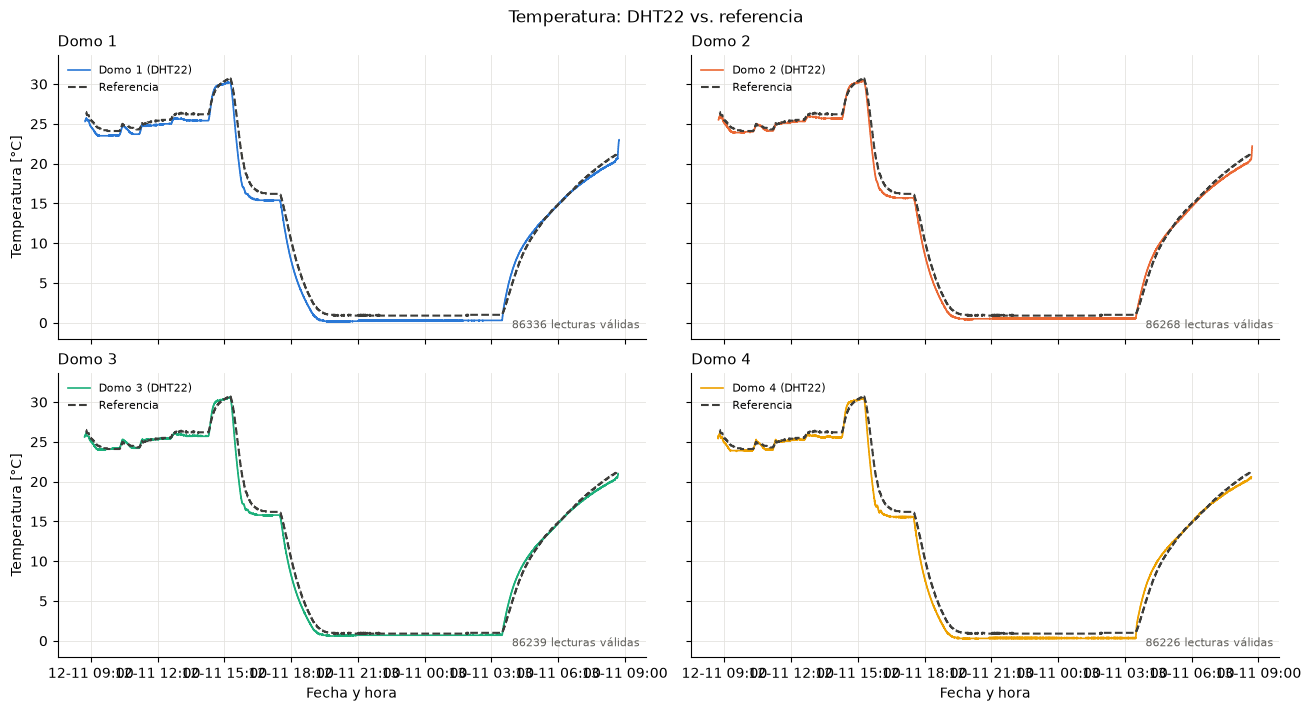

In [22]:
fig_dht_t, _ = graficar_vs_referencia(exp, "DHT_Temp", "AirT_C", "Temperatura [°C]",
                                      "Temperatura: DHT22 vs. referencia",
                                      margen=3, sensor="DHT22")
plt.show()

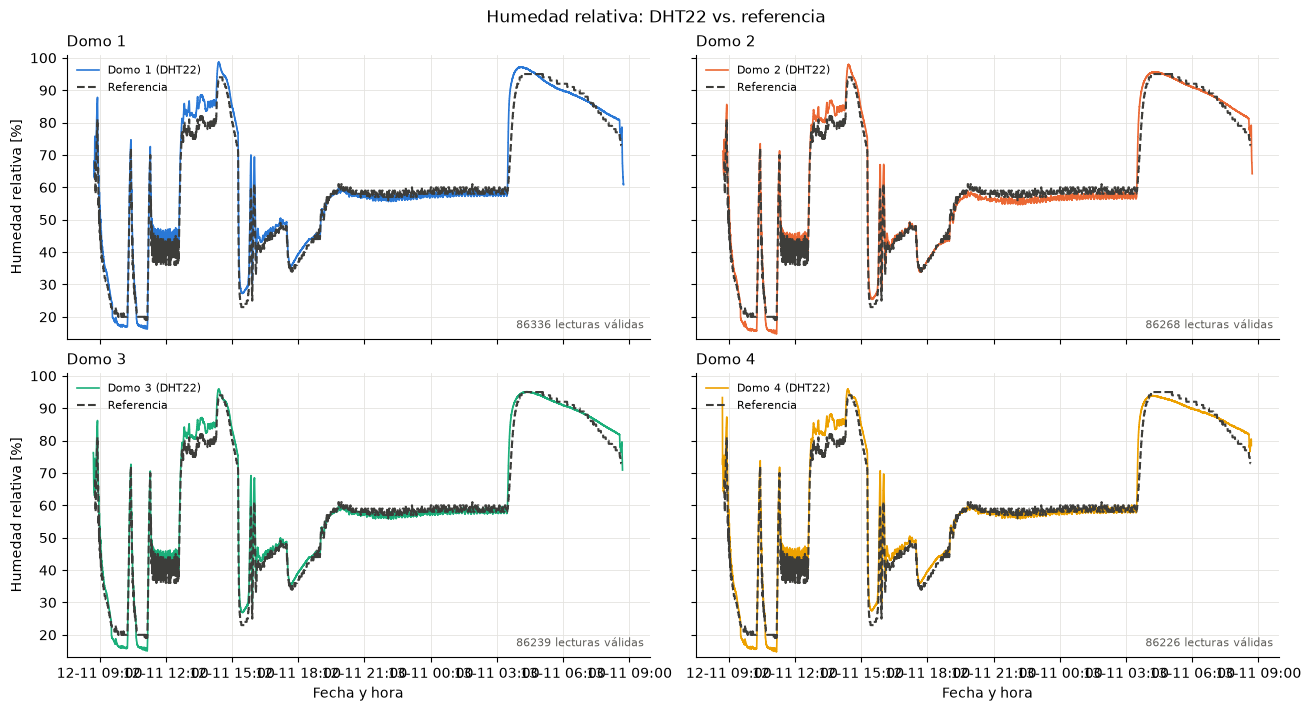

In [23]:
fig_dht_h, _ = graficar_vs_referencia(exp, "DHT_Hum", "RH", "Humedad relativa [%]",
                                      "Humedad relativa: DHT22 vs. referencia",
                                      margen=6, sensor="DHT22")
plt.show()

In [24]:
# ---------------------------------------------------------------------------
# Métricas de error de cada sensor contra la referencia -> `tabla_metricas`
# ---------------------------------------------------------------------------
# Qué columna del domo se compara con qué columna de la referencia.
COMPARACIONES = {
    ("SHT40", "Temperatura [°C]"): ("SHT_Temp", "AirT_C"),
    ("SHT40", "Humedad [%]"): ("SHT_Hum", "RH"),
    ("DHT22", "Temperatura [°C]"): ("DHT_Temp", "AirT_C"),
    ("DHT22", "Humedad [%]"): ("DHT_Hum", "RH"),
}
# La referencia registra cada 10 s y los domos cada 1 s: a cada lectura de la
# referencia se le asigna el promedio de 10 s del domo centrado en esa hora.
VENTANA = "10s"


def emparejar(domo, ref):
    """DataFrame con columnas 'domo' y 'ref' en las horas de la referencia."""
    domo = domo[~domo.index.duplicated()].sort_index()
    domo = domo.rolling(VENTANA, center=True).mean()
    domo = domo.reindex(ref.index, method="nearest", tolerance=pd.Timedelta("1s"))
    return pd.DataFrame({"domo": domo, "ref": ref}).dropna()


pares = {}
filas = []
ref = exp["Referencia"]
for nombre in ESTACIONES:
    for (sensor, variable), (col_domo, col_ref) in COMPARACIONES.items():
        p = emparejar(exp[nombre][col_domo], ref[col_ref])
        pares[(nombre, sensor, variable)] = p
        error = p["domo"] - p["ref"]
        filas.append({
            "estacion": nombre,
            "variable": variable,
            "sensor": sensor,
            "n": len(p),
            "sesgo": error.mean(),  # > 0: el sensor marca más que la referencia
            "r": p["domo"].corr(p["ref"]),
            "MAE": error.abs().mean(),
            "RMSE": np.sqrt((error**2).mean()),
        })

tabla_metricas = pd.DataFrame(filas)
tabla_metricas.round({"sesgo": 2, "r": 4, "MAE": 2, "RMSE": 2})

,estacion,variable,sensor,n,sesgo,r,MAE,RMSE
0,Domo 1,Temperatura [°C],SHT40,8593,-0.91,0.9994,0.92,0.99
1,Domo 1,Humedad [%],SHT40,8593,1.27,0.9791,7.36,9.50
2,Domo 1,Temperatura [°C],DHT22,8593,-0.65,0.9974,0.80,1.00
3,Domo 1,Humedad [%],DHT22,8593,1.15,0.9889,2.42,3.40
4,Domo 2,Temperatura [°C],SHT40,8593,-1.03,0.9991,1.03,1.15
5,Domo 2,Humedad [%],SHT40,8593,1.99,0.9863,7.35,9.14
6,Domo 2,Temperatura [°C],DHT22,8593,-0.43,0.9988,0.52,0.68
7,Domo 2,Humedad [%],DHT22,8593,0.24,0.9923,2.18,2.82
8,Domo 3,Temperatura [°C],SHT40,8593,-1.01,0.9984,1.03,1.19
9,Domo 3,Humedad [%],SHT40,8593,0.57,0.9896,4.22,5.21


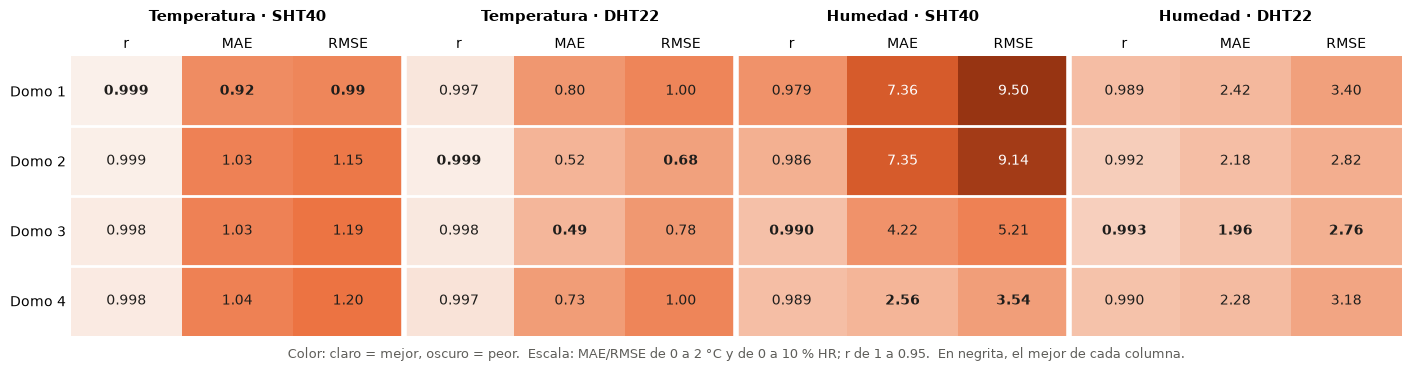

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# ---------------------------------------------------------------------------
# Escala de color: 0 = bueno (claro), 1 = malo (oscuro).
# MAE y RMSE: 0 -> límite de la tabla (sobre el límite queda en el color más oscuro).
# r: 1 -> R_MALO (bajo R_MALO queda en el color más oscuro).
# ---------------------------------------------------------------------------
LIMITE_ERROR = {"Temperatura [°C]": 2.0, "Humedad [%]": 10.0}
R_MALO = 0.95
CMAP_ERROR = LinearSegmentedColormap.from_list("error", ["#fbf3ee", "#f2a27e", "#eb6834", "#8a2c0d"])

VARIABLES = ["Temperatura [°C]", "Humedad [%]"]
SENSORES = ["SHT40", "DHT22"]
METRICAS = ["r", "MAE", "RMSE"]


def nivel_de_error(metrica, variable, valor):
    if metrica == "r":
        return np.clip((1 - valor) / (1 - R_MALO), 0, 1)
    return np.clip(valor / LIMITE_ERROR[variable], 0, 1)


def graficar_grilla(tabla):
    columnas = [(v, s, m) for v in VARIABLES for s in SENSORES for m in METRICAS]
    t = tabla.set_index(["estacion", "variable", "sensor"])

    valores = np.array([[t.loc[(e, v, s), m] for v, s, m in columnas] for e in ESTACIONES])
    niveles = np.array([[nivel_de_error(m, v, t.loc[(e, v, s), m]) for v, s, m in columnas]
                        for e in ESTACIONES])

    fig, ax = plt.subplots(figsize=(14, 3.6), layout="constrained")
    ax.imshow(niveles, cmap=CMAP_ERROR, vmin=0, vmax=1, aspect="auto")

    # Valor en cada celda; se destaca en negrita el mejor de cada columna.
    for j, (v, s, m) in enumerate(columnas):
        col = valores[:, j]
        mejor = np.nanargmax(col) if m == "r" else np.nanargmin(col)
        for i in range(len(ESTACIONES)):
            texto = f"{col[i]:.3f}" if m == "r" else f"{col[i]:.2f}"
            ax.text(j, i, texto, ha="center", va="center", fontsize=10,
                    fontweight="bold" if i == mejor else "normal",
                    color="white" if niveles[i, j] > 0.6 else "#1f1e1c")

    # Ejes y encabezados
    ax.set_yticks(range(len(ESTACIONES)), ESTACIONES)
    ax.set_xticks(range(len(columnas)), [m for _, _, m in columnas])
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for k in range(0, len(columnas), len(METRICAS)):
        v, s, _ = columnas[k]
        ax.text(k + 1, -0.95, f"{v.split(' ')[0]} · {s}", ha="center", va="bottom",
                fontsize=11, fontweight="bold")
        if k:
            ax.axvline(k - 0.5, color="white", lw=4)  # separa los grupos
    for i in range(1, len(ESTACIONES)):
        ax.axhline(i - 0.5, color="white", lw=2)
    ax.spines[:].set_visible(False)

    ax.set_xlabel(
        f"Color: claro = mejor, oscuro = peor.  Escala: MAE/RMSE de 0 a "
        f"{LIMITE_ERROR['Temperatura [°C]']:g} °C y de 0 a {LIMITE_ERROR['Humedad [%]']:g} % HR; "
        f"r de 1 a {R_MALO}.  En negrita, el mejor de cada columna.",
        fontsize=9, color="#5f5e5a", labelpad=8,
    )
    return fig, ax


fig_grilla, _ = graficar_grilla(tabla_metricas)
plt.show()


## Gráficos agrupados por sensor, con los periodos del experimento

In [26]:
# ---------------------------------------------------------------------------
# Periodos del experimento (consignas de la cámara), según el registro manual
# ---------------------------------------------------------------------------
PERIODOS = [
    # (inicio, fin, etiqueta, tipo)
    ("08:46", "11:09", "10 %HR", "humedad"),
    ("11:10", "12:35", "35 %HR", "humedad"),
    ("12:36", "14:15", "80 %HR", "humedad"),
    ("14:16", "15:16", "30 °C", "temperatura"),
    ("15:17", "17:28", "15 °C", "temperatura"),
    ("17:30", "21:00", "0 °C", "temperatura"),
]
PERIODOS = [
    (pd.Timestamp(f"{FECHA} {ini}"), pd.Timestamp(f"{FECHA} {fin}"), etiqueta, tipo)
    for ini, fin, etiqueta, tipo in PERIODOS
]
# Colores distintos a los de las estaciones para no confundir periodos con series.
COLOR_PERIODO = {"humedad": "#7b5cc4", "temperatura": "#8a8478"}


def marcar_periodos(ax):
    """Sombrea cada periodo (morado = consigna de humedad, gris = de temperatura),
    marca sus límites con líneas verticales y escribe la consigna arriba."""
    for k, (ini, fin, etiqueta, tipo) in enumerate(PERIODOS):
        color = COLOR_PERIODO[tipo]
        ax.axvspan(ini, fin, color=color, alpha=0.06 if k % 2 else 0.12, lw=0, zorder=0)
        for borde in (ini, fin):
            ax.axvline(borde, color=color, lw=0.8, ls=":", alpha=0.8, zorder=1)
        ax.text(ini + (fin - ini) / 2, 1.01, etiqueta, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=9, fontweight="bold", color=color)


def graficar_agrupado(exp, col_domo, col_ref, etiqueta, titulo, sensor):
    """Todas las estaciones (un sensor) y la referencia en un mismo gráfico,
    con los periodos del experimento marcados."""
    fig, ax = plt.subplots(figsize=(14, 5.5), layout="constrained")
    marcar_periodos(ax)

    for nombre in ESTACIONES:
        serie = exp[nombre][col_domo]
        ax.plot(serie.index, serie, lw=1, color=COLORES[nombre], label=f"{nombre} ({sensor})")
    ref = exp["Referencia"][col_ref]
    ax.plot(ref.index, ref, lw=1.8, ls="--", color=COLOR_REF, label="Referencia", zorder=5)

    ax.set_xlim(PERIODOS[0][0] - pd.Timedelta(minutes=10),
                PERIODOS[-1][1] + pd.Timedelta(minutes=10))
    ax.xaxis.set_major_locator(mdates.HourLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlabel(f"Hora ({FECHA})")
    ax.set_ylabel(etiqueta)
    ax.grid(True, axis="y", color=COLOR_GRILLA, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), frameon=False, fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=13, pad=22)
    return fig, ax

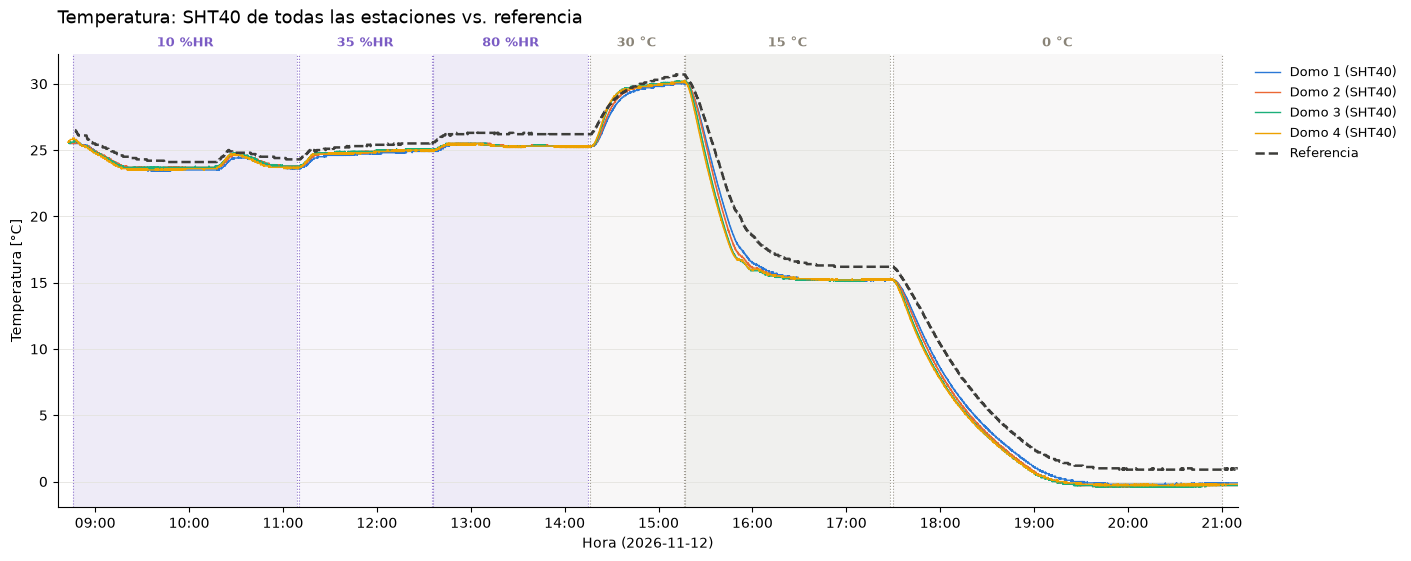

In [27]:
fig_agr_sht_t, _ = graficar_agrupado(exp, "SHT_Temp", "AirT_C", "Temperatura [°C]",
                                      "Temperatura: SHT40 de todas las estaciones vs. referencia", "SHT40")
plt.show()

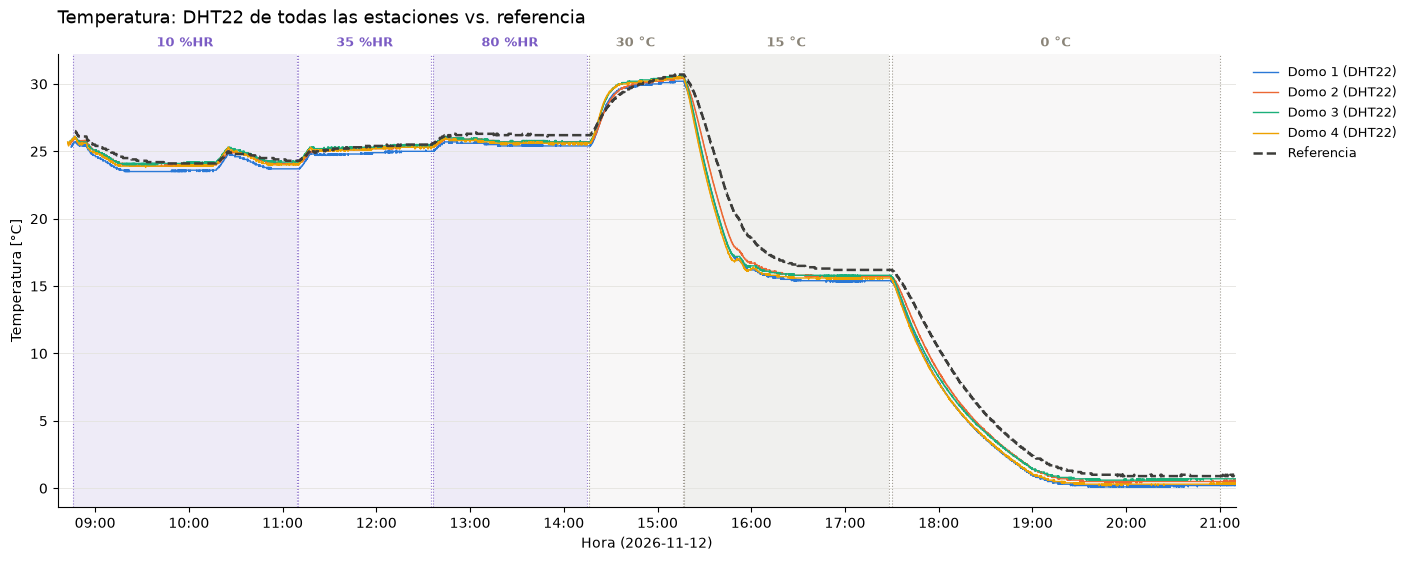

In [28]:
fig_agr_dht_t, _ = graficar_agrupado(exp, "DHT_Temp", "AirT_C", "Temperatura [°C]",
                                      "Temperatura: DHT22 de todas las estaciones vs. referencia", "DHT22")
plt.show()

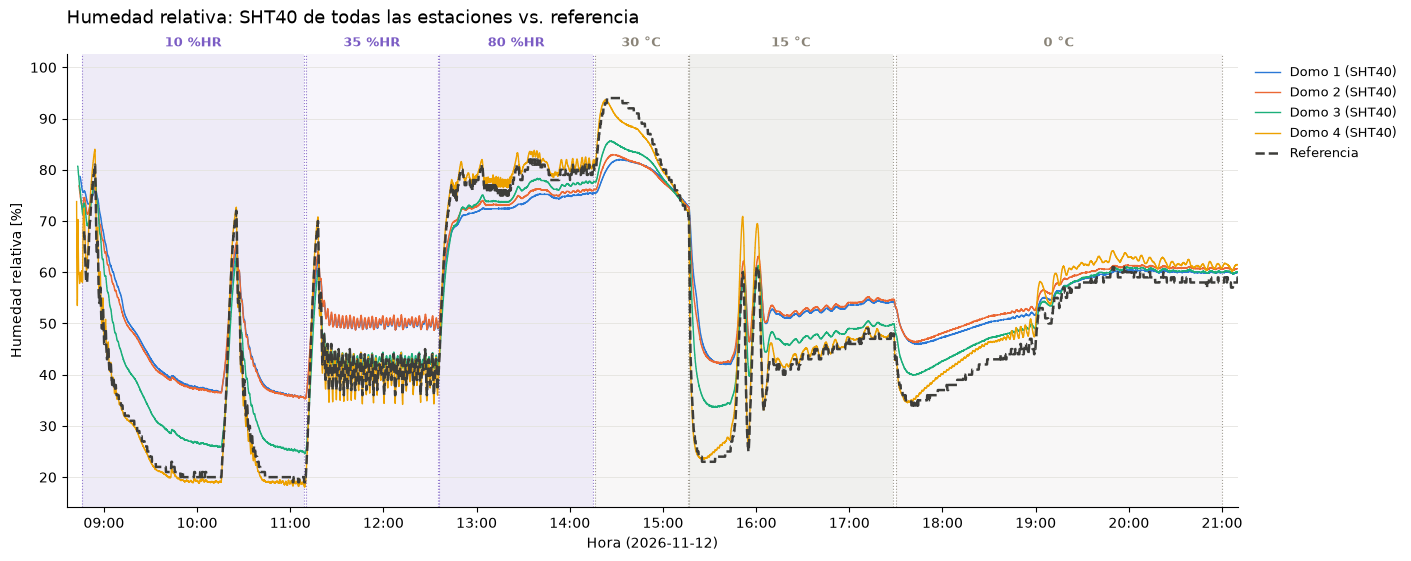

In [29]:
fig_agr_sht_h, _ = graficar_agrupado(exp, "SHT_Hum", "RH", "Humedad relativa [%]",
                                      "Humedad relativa: SHT40 de todas las estaciones vs. referencia", "SHT40")
plt.show()

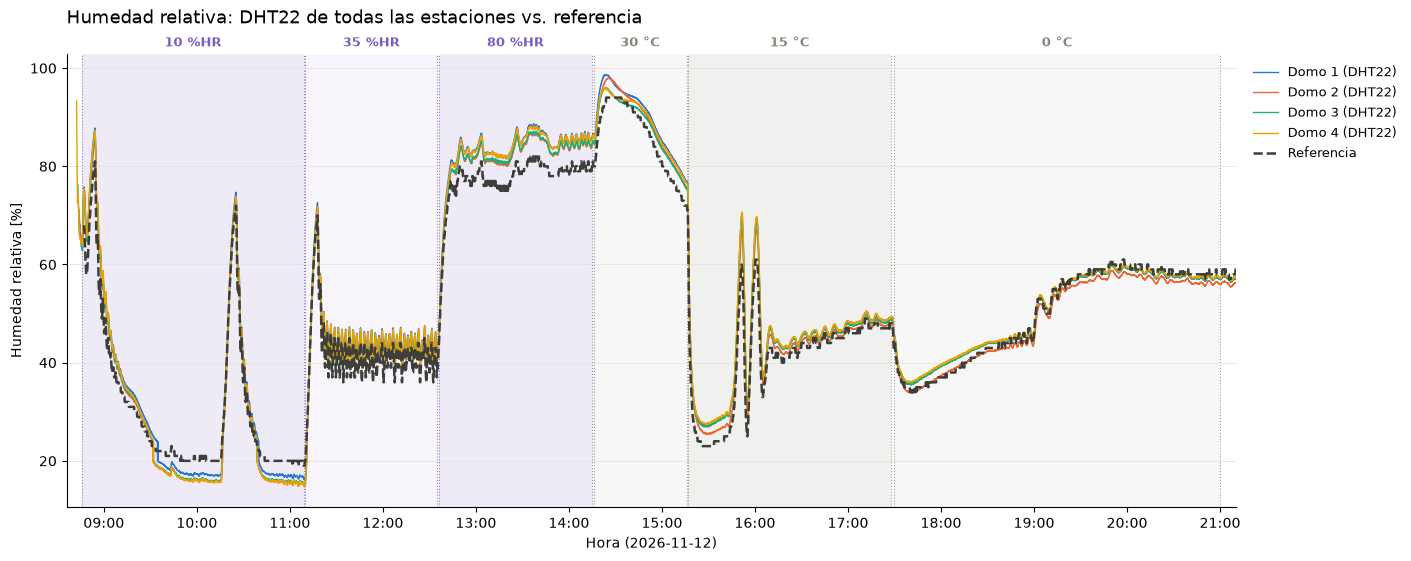

In [30]:
fig_agr_dht_h, _ = graficar_agrupado(exp, "DHT_Hum", "RH", "Humedad relativa [%]",
                                      "Humedad relativa: DHT22 de todas las estaciones vs. referencia", "DHT22")
plt.show()

## Calibración de Mediciones

Tramos usados para calibrar humedad (últimos 20 min estables de cada periodo)
periodo usado desde hasta  min estables  ref media  ref desv
 10 %HR    sí 10:49 11:09         20.17      19.93      0.25
 35 %HR    sí 12:14 12:34         17.50      40.75      2.19
 80 %HR    sí 13:55 14:13         18.67      79.59      0.68 

Tramos usados para calibrar temperatura (últimos 20 min estables de cada periodo)
periodo usado desde hasta  min estables  ref media  ref desv
  30 °C    sí 15:01 15:16         12.67       30.6      0.10
  15 °C    sí 17:08 17:28         20.17       16.2      0.00
   0 °C    sí 20:40 21:00         20.17        0.9      0.02 

Excluido 2026-11-12 10:15 -> 10:45: Puerta abierta para corregir cables (peak en 10 %HR)

Calibración Temperatura [°C]   (corregido = a + b · sensor)
estacion sensor  a (offset)  b (ganancia)     R2   n  RMSE estable antes  RMSE estable después  RMSE total antes  RMSE total después
  Domo 1  SHT40       1.122        0.9866 1.0000 318             

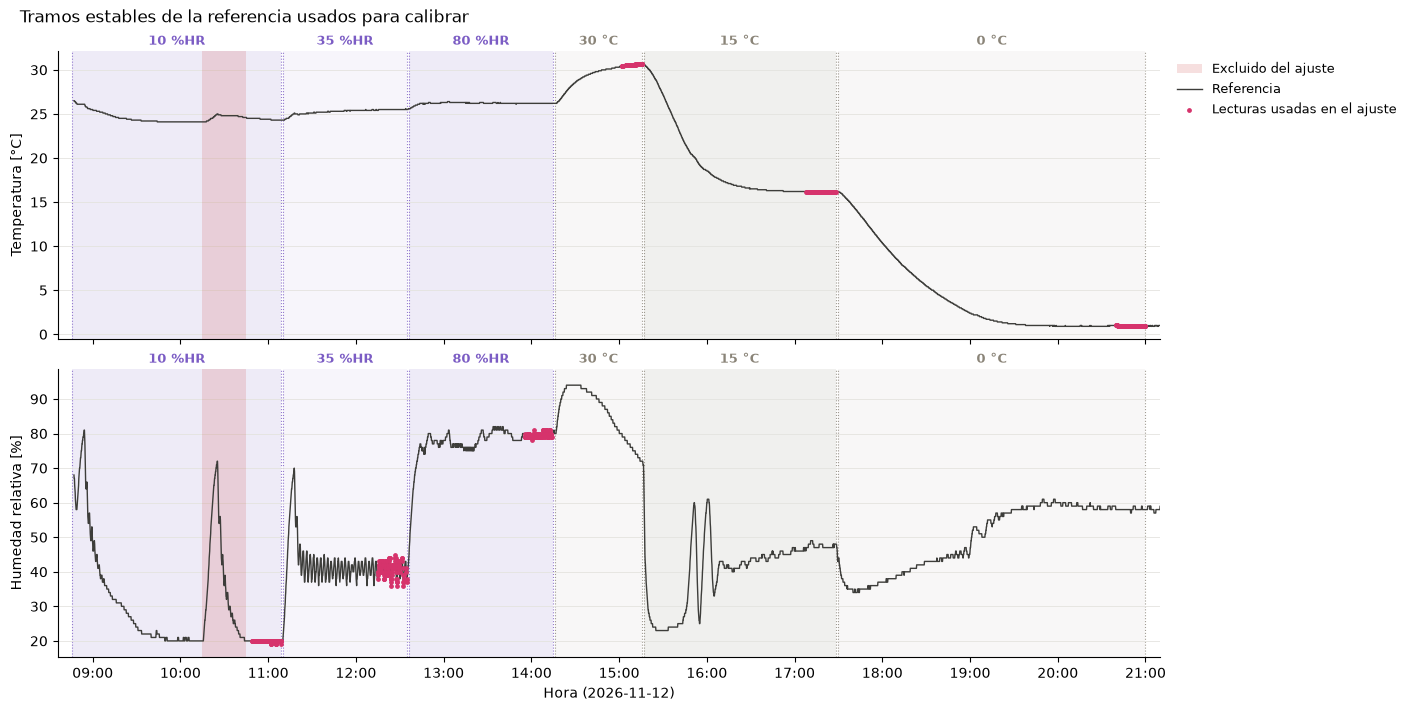

Tabla guardada en: coeficientes_calibracion.png


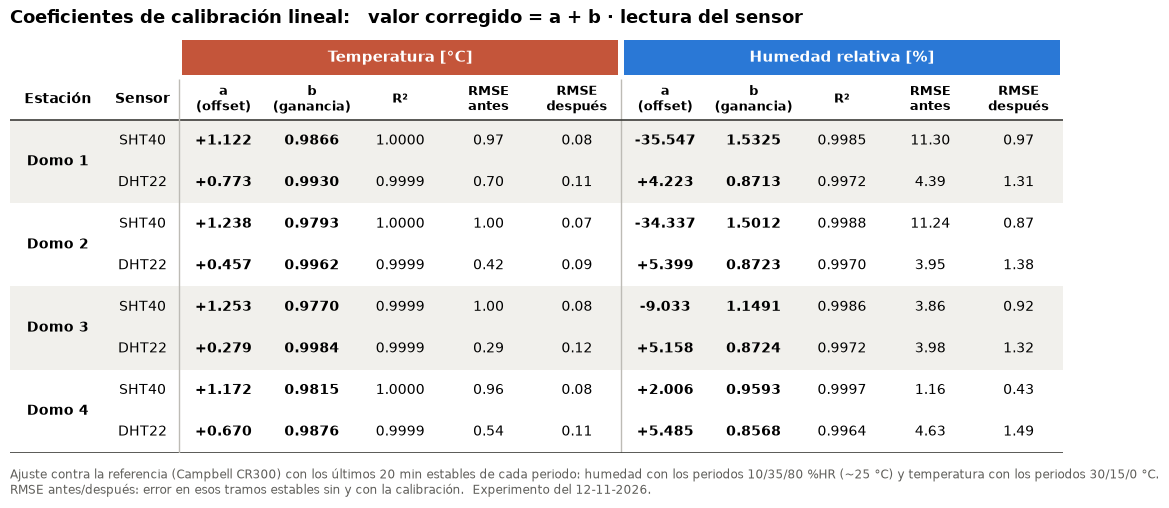

In [31]:
# ---------------------------------------------------------------------------
# Calibración lineal de cada sensor contra la referencia
#   valor_corregido = a + b * valor_sensor
#
# Diseño del experimento (6 periodos, ver PERIODOS):
#   - 10 %HR, 35 %HR, 80 %HR: se varió la humedad con temperatura ~25 °C
#     -> solo estos periodos se usan para calibrar HUMEDAD.
#   - 30 °C, 15 °C, 0 °C: se varió la temperatura con humedad libre
#     -> solo estos periodos se usan para calibrar TEMPERATURA.
#
# La cámara no siempre alcanzó la consigna (p. ej. en "10 %HR" la referencia
# quedó en ~20 %), así que NO se usa el valor nominal: se ajusta contra lo que
# midió la referencia, usando de cada periodo los últimos 20 min en que la
# referencia estuvo estable.
# ---------------------------------------------------------------------------
SENSORES_CAL = {
    # (sensor, variable): (columna del domo, columna de la referencia)
    ("SHT40", "Temperatura [°C]"): ("SHT_Temp", "AirT_C"),
    ("DHT22", "Temperatura [°C]"): ("DHT_Temp", "AirT_C"),
    ("SHT40", "Humedad [%]"): ("SHT_Hum", "RH"),
    ("DHT22", "Humedad [%]"): ("DHT_Hum", "RH"),
}
# Qué columna de la referencia se calibra con cada tipo de periodo.
COLUMNA_POR_TIPO = {"temperatura": "AirT_C", "humedad": "RH"}

# Intervalos que se eliminan del ajuste por eventos ajenos al experimento.
EXCLUIR_HORARIOS = [
    # (inicio, fin, motivo)
    ("2026-11-12 10:15", "2026-11-12 10:45",
     "Puerta abierta para corregir cables (peak en 10 %HR)"),
]

# Criterio de estabilidad, evaluado DENTRO de cada periodo con una ventana móvil
# centrada. Una lectura es estable si en su ventana:
#   - la desviación estándar es <= máx. desviación (ruido / oscilación del control), y
#   - la deriva (pendiente de la recta ajustada x duración de la ventana) es <= máx. deriva.
VENTANA_ESTABLE = "10min"
CRITERIO_ESTABLE = {
    # columna de la referencia: (máx. desviación, máx. deriva por ventana)
    "AirT_C": (0.15, 0.3),  # °C (al final de 30 °C la cámara aún sube ~0.25 °C / 10 min)
    "RH": (2.5, 1.5),       # % HR (al controlar humedad la cámara oscila ~±2 %)
}
# De cada periodo se usan los últimos ULTIMOS_ESTABLES de lecturas estables.
# Si un periodo tiene menos de MIN_POR_PERIODO estables, no se usa.
ULTIMOS_ESTABLES = pd.Timedelta(minutes=20)
MIN_POR_PERIODO = pd.Timedelta(minutes=5)
# Periodos que NO se usan para ajustar (por etiqueta), p. ej. ["30 °C"].
EXCLUIR_CAL = []


def es_estable(serie, max_desv, max_deriva):
    """Serie booleana: True donde la serie está estable."""
    ventana = pd.Timedelta(VENTANA_ESTABLE)
    t = pd.Series((serie.index - serie.index[0]).total_seconds(), index=serie.index)
    rodante = lambda s: s.rolling(ventana, center=True)
    desv = rodante(serie).std()
    pendiente = rodante(serie).cov(t) / rodante(t).var()  # unidades por segundo
    deriva = pendiente.abs() * ventana.total_seconds()
    return (desv <= max_desv) & (deriva <= max_deriva)


def rmse(x, y):
    return float(np.sqrt(np.mean((np.asarray(x) - np.asarray(y)) ** 2)))


# ---------------------------------------------------------------------------
# 1) Selección de los tramos estables de la referencia
# ---------------------------------------------------------------------------
ref = exp["Referencia"]
PASO_REF = ref.index.to_series().diff().median()  # 10 s

# Lecturas dentro de los intervalos excluidos (puerta abierta, etc.).
EXCLUIDO = pd.Series(False, index=ref.index)
for ini, fin, _ in EXCLUIR_HORARIOS:
    EXCLUIDO |= (ref.index >= pd.Timestamp(ini)) & (ref.index <= pd.Timestamp(fin))
ref_util = ref[~EXCLUIDO]

# SELECCION[col] = True en las lecturas de la referencia que se usan para ajustar `col`.
SELECCION = {col: pd.Series(False, index=ref.index) for col in COLUMNA_POR_TIPO.values()}
filas_sel = []
for ini, fin, etiqueta, tipo in PERIODOS:
    if etiqueta in EXCLUIR_CAL:
        continue
    col = COLUMNA_POR_TIPO[tipo]
    tramo = ref_util.loc[ini:fin]
    estable = es_estable(tramo[col], *CRITERIO_ESTABLE[col])
    if col == "RH":
        # La humedad relativa depende de la temperatura: se exige que ambas estén estables.
        estable &= es_estable(tramo["AirT_C"], *CRITERIO_ESTABLE["AirT_C"])

    horas = tramo.index[estable.to_numpy()]
    if len(horas):
        horas = horas[horas >= horas.max() - ULTIMOS_ESTABLES]
    duracion = len(horas) * PASO_REF
    usado = duracion >= MIN_POR_PERIODO
    if usado:
        SELECCION[col].loc[horas] = True
    valores = ref.loc[horas, col]
    filas_sel.append({
        "variable": "Temperatura" if col == "AirT_C" else "Humedad",
        "periodo": etiqueta,
        "usado": "sí" if usado else "no",
        "desde": horas.min().strftime("%H:%M") if len(horas) else "-",
        "hasta": horas.max().strftime("%H:%M") if len(horas) else "-",
        "min estables": duracion.total_seconds() / 60,
        "ref media": valores.mean(),
        "ref desv": valores.std(),
    })

tabla_seleccion = pd.DataFrame(filas_sel)
for variable, grupo in tabla_seleccion.groupby("variable", sort=False):
    print(f"Tramos usados para calibrar {variable.lower()} (últimos "
          f"{ULTIMOS_ESTABLES.total_seconds() / 60:g} min estables de cada periodo)")
    print(grupo.drop(columns="variable").round(2).to_string(index=False), "\n")
for ini, fin, motivo in EXCLUIR_HORARIOS:
    print(f"Excluido {ini} -> {fin[-5:]}: {motivo}")
print()


# ---------------------------------------------------------------------------
# 2) Ajuste por estación, sensor y variable (ref ≈ a + b * domo)
# ---------------------------------------------------------------------------
filas = []
for nombre in ESTACIONES:
    for (sensor, variable), (col_domo, col_ref) in SENSORES_CAL.items():
        p_total = emparejar(exp[nombre][col_domo], ref[col_ref])
        p_total = p_total[~EXCLUIDO.reindex(p_total.index, fill_value=False)]  # todo el experimento
        p_cal = p_total[SELECCION[col_ref].reindex(p_total.index, fill_value=False)]

        b, a = np.polyfit(p_cal["domo"], p_cal["ref"], 1)
        cal_corr = a + b * p_cal["domo"]
        total_corr = a + b * p_total["domo"]

        filas.append({
            "estacion": nombre, "sensor": sensor, "variable": variable,
            "a (offset)": a, "b (ganancia)": b,
            "R2": np.corrcoef(p_cal["domo"], p_cal["ref"])[0, 1] ** 2,
            "n": len(p_cal),
            "RMSE estable antes": rmse(p_cal["domo"], p_cal["ref"]),
            "RMSE estable después": rmse(cal_corr, p_cal["ref"]),
            "RMSE total antes": rmse(p_total["domo"], p_total["ref"]),
            "RMSE total después": rmse(total_corr, p_total["ref"]),
        })

tabla_calibracion = pd.DataFrame(filas)

# Coeficientes listos para usar: CALIBRACION[(estacion, sensor, variable)] = (a, b)
CALIBRACION = {
    (f["estacion"], f["sensor"], f["variable"]): (f["a (offset)"], f["b (ganancia)"])
    for f in filas
}

# Datos corregidos: copia de `exp` con columnas nuevas *_cal (las originales no se tocan).
exp_cal = {"Referencia": exp["Referencia"]}
for nombre in ESTACIONES:
    df = exp[nombre].copy()
    for (sensor, variable), (col_domo, _) in SENSORES_CAL.items():
        a, b = CALIBRACION[(nombre, sensor, variable)]
        df[f"{col_domo}_cal"] = a + b * df[col_domo]
    exp_cal[nombre] = df

for variable in ["Temperatura [°C]", "Humedad [%]"]:
    print(f"Calibración {variable}   (corregido = a + b · sensor)")
    print(tabla_calibracion[tabla_calibracion["variable"] == variable]
          .drop(columns="variable").round({"a (offset)": 3, "b (ganancia)": 4, "R2": 4,
                                           "RMSE estable antes": 2, "RMSE estable después": 2,
                                           "RMSE total antes": 2, "RMSE total después": 2})
          .to_string(index=False), "\n")


# ---------------------------------------------------------------------------
# 3) Gráfico de control: qué lecturas de la referencia se usaron en el ajuste
# ---------------------------------------------------------------------------
fig_sel, ejes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, layout="constrained")
for ax, (col, etiqueta) in zip(ejes, [("AirT_C", "Temperatura [°C]"),
                                      ("RH", "Humedad relativa [%]")]):
    marcar_periodos(ax)
    for k, (ini, fin, motivo) in enumerate(EXCLUIR_HORARIOS):
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color="#c92a2a", alpha=0.15,
                   lw=0, zorder=2, label="Excluido del ajuste" if k == 0 else None)
    ax.plot(ref.index, ref[col], lw=1, color=COLOR_REF, label="Referencia")
    usados = ref.loc[SELECCION[col], col]
    ax.scatter(usados.index, usados, s=6, color="#d6336c", zorder=5,
               label="Lecturas usadas en el ajuste")
    ax.set_ylabel(etiqueta)
    ax.grid(True, axis="y", color=COLOR_GRILLA, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
ejes[0].legend(loc="upper left", bbox_to_anchor=(1.005, 1), frameon=False, fontsize=9)
ejes[-1].set_xlim(PERIODOS[0][0] - pd.Timedelta(minutes=10),
                  PERIODOS[-1][1] + pd.Timedelta(minutes=10))
ejes[-1].xaxis.set_major_locator(mdates.HourLocator())
ejes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ejes[-1].set_xlabel(f"Hora ({FECHA})")
fig_sel.suptitle("Tramos estables de la referencia usados para calibrar", x=0.01, ha="left")
plt.show()


# ---------------------------------------------------------------------------
# 4) Tabla de coeficientes como imagen (se muestra y se guarda en PNG)
# ---------------------------------------------------------------------------
from matplotlib.patches import Rectangle

RUTA_TABLA = BASE / "coeficientes_calibracion.png"
VARIABLES_TABLA = [
    # (variable en tabla_calibracion, título del grupo, color del encabezado)
    ("Temperatura [°C]", "Temperatura [°C]", "#c4553a"),
    ("Humedad [%]", "Humedad relativa [%]", "#2a78d6"),
]
CAMPOS_TABLA = [
    # (columna en tabla_calibracion, encabezado, formato)
    ("a (offset)", "a\n(offset)", "{:+.3f}"),
    ("b (ganancia)", "b\n(ganancia)", "{:.4f}"),
    ("R2", "R²", "{:.4f}"),
    ("RMSE estable antes", "RMSE\nantes", "{:.2f}"),
    ("RMSE estable después", "RMSE\ndespués", "{:.2f}"),
]


def graficar_tabla_coeficientes(tabla):
    t = tabla.set_index(["estacion", "sensor", "variable"])
    sensores = list(dict.fromkeys(s for s, _ in SENSORES_CAL))  # SHT40, DHT22
    filas = [(e, s) for e in ESTACIONES for s in sensores]
    n_campos = len(CAMPOS_TABLA)
    anchos = [1.3, 1.0] + [1.2] * (len(VARIABLES_TABLA) * n_campos)
    x = np.concatenate([[0], np.cumsum(anchos)])
    n = len(filas) + 2  # 2 filas de encabezado

    fig, ax = plt.subplots(figsize=(x[-1] * 0.95, n * 0.42 + 1.2))
    ax.set_xlim(0, x[-1])
    ax.set_ylim(n, 0)
    ax.axis("off")

    def celda(col, fila, texto, **kw):
        ax.text((x[col] + x[col + 1]) / 2, fila + 0.5, texto, ha="center", va="center", **kw)

    # Encabezados
    celda(0, 1, "Estación", fontweight="bold")
    celda(1, 1, "Sensor", fontweight="bold")
    for g, (_, titulo, color) in enumerate(VARIABLES_TABLA):
        c0, c1 = 2 + g * n_campos, 2 + (g + 1) * n_campos
        ax.add_patch(Rectangle((x[c0] + 0.04, 0.08), x[c1] - x[c0] - 0.08, 0.84,
                               color=color, lw=0))
        ax.text((x[c0] + x[c1]) / 2, 0.5, titulo, ha="center", va="center",
                color="white", fontweight="bold", fontsize=11)
        for k, (_, encabezado, _) in enumerate(CAMPOS_TABLA):
            celda(c0 + k, 1, encabezado, fontweight="bold", fontsize=9)
        if g:
            ax.vlines(x[c0], 1, n, color="#bdbbb5", lw=1)
    ax.hlines(2, 0, x[-1], color="#3d3d3a", lw=1.2)
    ax.hlines(n, 0, x[-1], color="#3d3d3a", lw=1.2)
    ax.vlines(x[2], 1, n, color="#bdbbb5", lw=1)

    # Datos (fondo alternado por estación)
    for i, (estacion, sensor) in enumerate(filas):
        fila = 2 + i
        if (i // len(sensores)) % 2 == 0:
            ax.add_patch(Rectangle((0, fila), x[-1], 1, color="#f1f0ec", lw=0, zorder=0))
        if i % len(sensores) == 0:
            ax.text((x[0] + x[1]) / 2, fila + len(sensores) / 2, estacion,
                    ha="center", va="center", fontweight="bold")
        celda(1, fila, sensor)
        for g, (variable, _, _) in enumerate(VARIABLES_TABLA):
            for k, (campo, _, fmt) in enumerate(CAMPOS_TABLA):
                valor = t.loc[(estacion, sensor, variable), campo]
                celda(2 + g * n_campos + k, fila, fmt.format(valor),
                      fontweight="bold" if campo.startswith(("a ", "b ")) else "normal")

    ax.set_title("Coeficientes de calibración lineal:   valor corregido = a + b · lectura del sensor",
                 loc="left", fontsize=13, fontweight="bold", pad=10)
    ax.text(0, n + 0.35,
            f"Ajuste contra la referencia (Campbell CR300) con los últimos "
            f"{ULTIMOS_ESTABLES.total_seconds() / 60:g} min estables de cada periodo: humedad con "
            f"los periodos 10/35/80 %HR (~25 °C) y temperatura con los periodos 30/15/0 °C.\n"
            f"RMSE antes/después: error en esos tramos estables sin y con la calibración.  "
            f"Experimento del {pd.Timestamp(FECHA):%d-%m-%Y}.",
            ha="left", va="top", fontsize=8.5, color="#5f5e5a")
    return fig, ax


fig_tabla, _ = graficar_tabla_coeficientes(tabla_calibracion)
fig_tabla.savefig(RUTA_TABLA, dpi=200, bbox_inches="tight", facecolor="white")
print(f"Tabla guardada en: {RUTA_TABLA.name}")
plt.show()